In [ ]:
#importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [ ]:
#loading data training data
df=pd.read_csv("/content/train.csv")
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.isnull().sum()   #checking null values

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
#df['Cabin'].value_counts()

In [ ]:
#removing unwanted variables
up_df=df.drop(['PassengerId','Name','Ticket'],axis=1)
up_df.head(2)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C


In [ ]:
#filling null values
up_df['Cabin']=up_df['Cabin'].fillna(up_df['Cabin'].mode()[0])
up_df['Age']=up_df['Age'].fillna(up_df['Age'].median())
up_df['Embarked']=up_df['Embarked'].fillna(up_df['Embarked'].mode()[0])

In [ ]:
#up_df.isnull().sum()

In [ ]:
#selecting variables which are more usefull for model building
#survived vs pclass --> both are ordinal categrial values so we use non peremetric test chisqure test
table = pd.crosstab(df['Pclass'], df['Survived'])
print(table)

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


In [ ]:
#H0=pclass and survived are independent
#H1=pclass and survived are dependent

from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(table)
print(chi2)
print(round(p_value))
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")

102.88898875696056
0
Reject the null hypothesis and conclude there is a relation


In [ ]:
#survived and sex
table = pd.crosstab(df['Sex'], df['Survived'])
print(table)


Survived    0    1
Sex               
female     81  233
male      468  109


In [ ]:
#H0=sex and survial are independent
#H1=sex and survival has dependent

from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(table)
print(chi2)
print((p_value))
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")

260.71702016732104
1.1973570627755645e-58
Reject the null hypothesis and conclude there is a relation


In [ ]:
#servival vs age

0.5102446555756495


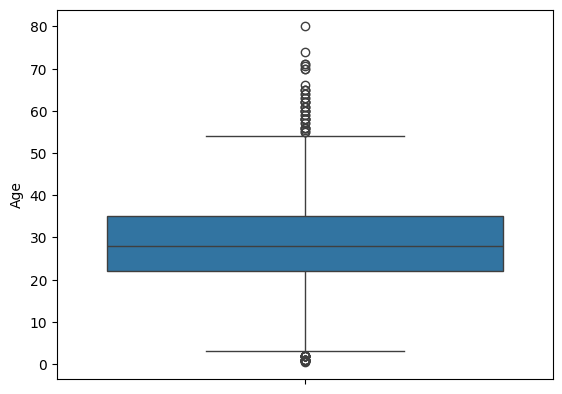

In [ ]:
sns.boxplot(up_df['Age'])
print(up_df['Age'].skew())

In [ ]:
#here the data is not normal the normality assumnations are failed so useing non prematric test
#mannwhitneyu

from scipy.stats import mannwhitneyu
age_survived = df[df['Survived'] == 1]['Age'].dropna()
age_not_survived = df[df['Survived'] == 0]['Age'].dropna()
stat, p_value = mannwhitneyu(
    age_survived,
    age_not_survived,
    alternative='two-sided'
)

print("U-statistic:", stat)
print("p-value:", p_value)

U-statistic: 57682.0
p-value: 0.16049252477737763


In [ ]:
#H0=age and survivall are independent
#H1=age and survival are dependent

if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")

Fail to reject the null hypothesis and conclude there is no relation


In [ ]:
up_df['SibSp'].skew()

np.float64(3.6953517271630565)

In [ ]:
#survived and sibsp
#observing that there is heigh skewness the data can't be normal so i useing non parametric test

from scipy.stats import mannwhitneyu
sibsp_survived = df[df['Survived'] == 1]['SibSp']
sibsp_not_survived = df[df['Survived'] == 0]['SibSp']

stat, p_value = mannwhitneyu(
    sibsp_survived,
    sibsp_not_survived,
    alternative='two-sided'
)

print("U-statistic:", stat)
print("p-value:", p_value)
#H0=survived and sibsp are independent
#H1=survived and sibsp are dependent
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")



U-statistic: 101983.0
p-value: 0.008016684059168793
Reject the null hypothesis and conclude there is a relation


In [ ]:
#survived vs parch
#using same approach
from scipy.stats import mannwhitneyu
parch_survived = df[df['Survived'] == 1]['Parch']
parch_not_survived = df[df['Survived'] == 0]['Parch']

stat, p_value = mannwhitneyu(
    parch_survived,
    parch_not_survived,
    alternative='two-sided'
)

print("U-statistic:", stat)
print("p-value:", (p_value))
#H0=survival and parch are independent
#H1=survival and parch are dependent
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")


U-statistic: 105373.0
p-value: 3.712490908378456e-05
Reject the null hypothesis and conclude there is a relation


In [ ]:
#survivrd vs fare
#using same approach
from scipy.stats import mannwhitneyu
fare_survived = df[df['Survived'] == 1]['Fare']
fare_not_survived = df[df['Survived'] == 0]['Fare']

stat, p_value = mannwhitneyu(
    fare_survived,
    fare_not_survived,
    alternative='two-sided'
)

print("U-statistic:", stat)
print("p-value:", (p_value))
#H0=survived and fare are indenpendent
#H1=survived and fare are depenedent
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")

U-statistic: 129951.5
p-value: 4.553477179250237e-22
Reject the null hypothesis and conclude there is a relation


In [ ]:
#here both are categorical variables so we use chiaquere test
#survived vs cabine
cross_table=pd.crosstab(up_df['Cabin'],up_df['Survived'])
#print(cross_table)

#H0=cabin and survial are independent
#H1=cabin and survival has dependent

from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(table)
print(chi2)
print((p_value))
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")



260.71702016732104
1.1973570627755645e-58
Reject the null hypothesis and conclude there is a relation


In [ ]:
#survived vs embarked
cross_table=pd.crosstab(up_df['Embarked'],up_df['Survived'])
cross_table

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,219


In [ ]:
#H0=embarked and survial are independent
#H1=embarked and survival has dependent

from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(table)
print(chi2)
print((p_value))
if p_value < 0.05:
    print("Reject the null hypothesis and conclude there is a relation")
else:
    print("Fail to reject the null hypothesis and conclude there is no relation")


260.71702016732104
1.1973570627755645e-58
Reject the null hypothesis and conclude there is a relation


In [ ]:
#concluding that pclass and survival has relation we need to take for model building

#concluding that sex and survival has relation we need to use for model bilding

#concluding that age and survival has no relation

#concluding that survived and sibsp has relation

#concluding that survival and parch has relation

#concluding that survival and fare has relation
#concluding the there is a relation between the cabin and survial
#concluding there is a relation between the embarked and survival

In [ ]:
#now building the model which has relation with target
up_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,B96 B98,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,B96 B98,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,B96 B98,S


In [ ]:
final_df=up_df.drop(columns=['Age'])
final_df.head(2)

,Survived,Pclass,Sex,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,1,0,7.2500,B96 B98,S
1,1,1,female,1,0,71.2833,C85,C


In [ ]:
final_df.skew(numeric_only=True)

,0
Survived,0.478523
Pclass,-0.630548
SibSp,3.695352
Parch,2.749117
Fare,4.787317


In [ ]:
#transforming the outliers
final_df['Fare']=np.log1p(final_df['Fare'])

In [ ]:
final_df.skew(numeric_only=True)

,0
Survived,0.478523
Pclass,-0.630548
SibSp,3.695352
Parch,2.749117
Fare,0.394928


In [ ]:
#encoding categorical variables
final_df=pd.get_dummies(final_df,columns=['Sex','Embarked'],dtype=int,drop_first=True)
final_df.head()

,Survived,Pclass,SibSp,Parch,Fare,Cabin,Sex_male,Embarked_Q,Embarked_S
0,0,3,1,0,2.110213,B96 B98,1,0,1
1,1,1,1,0,4.280593,C85,0,0,0
2,1,3,0,0,2.188856,B96 B98,0,0,1
3,1,1,1,0,3.990834,C123,0,0,1
4,0,3,0,0,2.202765,B96 B98,1,0,1


In [ ]:
final_df.drop(columns=['Cabin'],inplace=True)
final_df.head(1)

,Survived,Pclass,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,1,0,2.110213,1,0,1


In [ ]:
final_df.shape

(891, 8)

In [ ]:
x=final_df.drop(columns=['Survived'])
y=final_df['Survived']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)


In [ ]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 7)
(179, 7)
(712,)
(179,)


In [ ]:
#scaling the numeric columns
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train[['SibSp','Parch','Fare']]=sc.fit_transform(x_train[['SibSp','Parch','Fare']])
x_test[['SibSp','Parch','Fare']]=sc.transform(x_test[['SibSp','Parch','Fare']])

In [ ]:
print(x_train.shape)
print(x_test.shape)

(712, 7)
(179, 7)


In [ ]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
y_proba=model.predict_proba(x_test)[:,1]

In [ ]:
#y_proba

In [ ]:

from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve,f1_score

In [ ]:
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(roc_auc_score(y_test,y_proba))

0.7597765363128491
[[84 21]
 [22 52]]
              precision    recall  f1-score   support

           0       0.79      0.80      0.80       105
           1       0.71      0.70      0.71        74

    accuracy                           0.76       179
   macro avg       0.75      0.75      0.75       179
weighted avg       0.76      0.76      0.76       179

0.8708494208494209


In [ ]:
print(f1_score(y_test,y_pred))

0.7074829931972789


In [ ]:
test_df=pd.read_csv("/content/test.csv")
test_df.head(2)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S


In [ ]:
test_df.drop(columns=['PassengerId','Name','Ticket','Cabin','Age'],inplace=True)
test_df.head(2)

,Pclass,Sex,SibSp,Parch,Fare,Embarked
0,3,male,0,0,7.8292,Q
1,3,female,1,0,7.0000,S


In [ ]:
test_df=pd.get_dummies(test_df,columns=['Sex','Embarked'],dtype=int,drop_first=True)
test_df.head(2)

,Pclass,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,0,0,7.8292,1,1,0
1,3,1,0,7.0000,0,0,1


In [ ]:
test_df.isnull().sum()

,0
Pclass,0
SibSp,0
Parch,0
Fare,1
Sex_male,0
Embarked_Q,0
Embarked_S,0


In [ ]:
test_df['Fare']=test_df['Fare'].fillna(test_df['Fare'].median())

In [ ]:
test_df.isnull().sum()

,0
Pclass,0
SibSp,0
Parch,0
Fare,0
Sex_male,0
Embarked_Q,0
Embarked_S,0


In [ ]:
sc=StandardScaler()
test_df[['SibSp','Parch','Fare']]=sc.fit_transform(test_df[['SibSp','Parch','Fare']])

In [ ]:
test_df.head()

,Pclass,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,-0.499470,-0.400248,-0.497413,1,1,0
1,3,0.616992,-0.400248,-0.512278,0,0,1
2,2,-0.499470,-0.400248,-0.464100,1,1,0
3,3,-0.499470,-0.400248,-0.482475,1,0,1
4,3,0.616992,0.619896,-0.417492,0,0,1


In [ ]:
predictions=model.predict(test_df)

In [ ]:
len(predictions)

418

In [ ]:
len(test_df)

418

In [ ]:
original_test_df = pd.read_csv("/content/test.csv")
predictions_df = pd.DataFrame({'PassengerId': original_test_df['PassengerId'], 'Survived': predictions})
predictions_df.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [ ]:
predictions_df.to_csv('submissions_M2.csv',index=False)